# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
df = pd.read_csv(DATA_PATH)
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print(df.info())
print("Nulos:", df.isna().sum().sum())
print("Duplicados:", df.duplicated().sum())
print("Clases:\n", df["target"].value_counts().sort_index())
print(df.describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

**Conclusión de calidad:** Los datos tienen 178 registros, 13 variables de entrada y una columna objetivo. Revisé los valores faltantes, los duplicados y el balance de clases antes de dividir los datos. No hace falta eliminar filas ni inventar valores; de todas formas, la imputación queda dentro del pipeline para que el proceso sea reutilizable.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df["target"], random_state=RANDOM_STATE)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

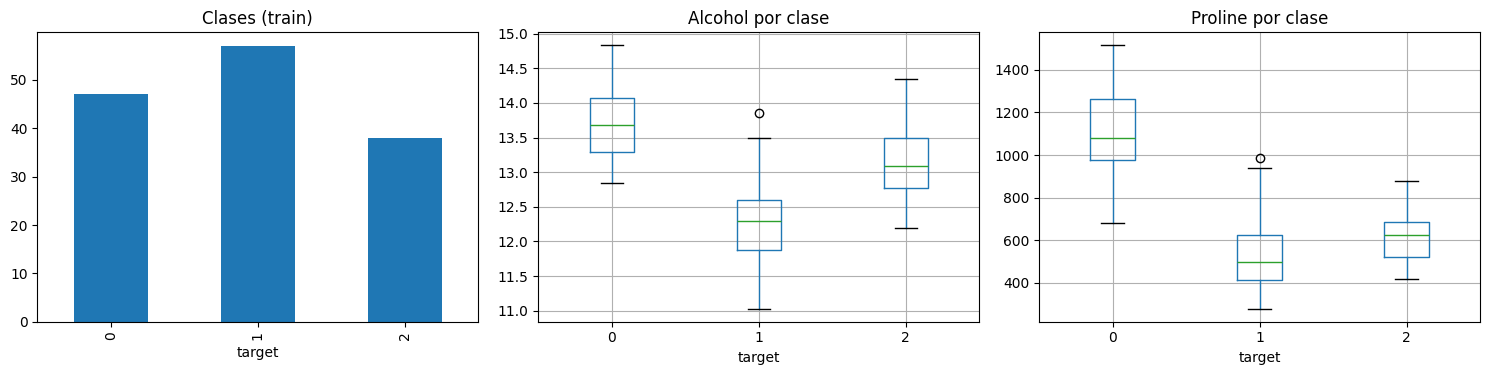

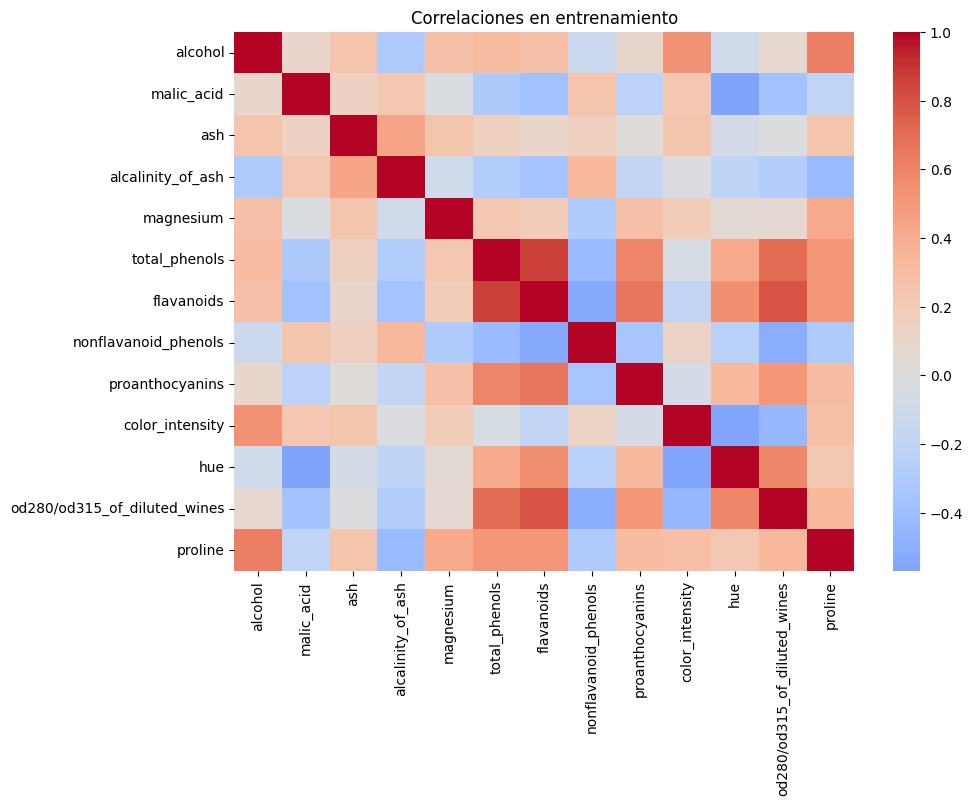

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
train_df["target"].value_counts().sort_index().plot.bar(ax=axes[0], title="Clases (train)")
train_df.boxplot(column="alcohol", by="target", ax=axes[1]); axes[1].set_title("Alcohol por clase")
train_df.boxplot(column="proline", by="target", ax=axes[2]); axes[2].set_title("Proline por clase")
plt.suptitle(""); plt.tight_layout(); plt.show()
plt.figure(figsize=(10, 7)); sns.heatmap(train_df.drop(columns="target").corr(), cmap="coolwarm", center=0); plt.title("Correlaciones en entrenamiento"); plt.show()

**Hallazgos:**

1. Las clases no tienen exactamente el mismo número de ejemplos. Por eso hice una división estratificada.
2. Variables como `alcohol` y `proline` muestran diferencias entre grupos; pueden servir para clasificar.
3. Hay variables con correlaciones entre sí, así que vale la pena comparar modelos lineales con árboles y KNN, en lugar de elegir uno sin probar.

## 4. Persistencia de datos y contrato

In [8]:
train_df.reset_index(drop=True).to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.reset_index(drop=True).to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)
contract = {"target":"target", "features":[c for c in df.columns if c != "target"], "random_state": RANDOM_STATE, "test_size":0.20}
(ARTIFACTS_DIR / "data_contract.json").write_text(json.dumps(contract, indent=2), encoding="utf-8")

347

In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.